# FNN Training / NASA dataset
We first setup the environment (installed numpy, pandas, matplotlib) and we read the main file

In [167]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from sklearn.model_selection import train_test_split

main = pd.read_csv(r'.\training\cleaned_dataset\metadata.csv')

Now we crop the file down to only those file (test) regarding discharge

In [ ]:
class DischargeCleaned():
    def __init__(self, dataset):
        self.ds = dataset[dataset['type'] == 'discharge']

    def selector(self, id):
        return self.ds[self.ds.battery_id == id].reset_index(drop=True)

discharge = DischargeCleaned(main)

In [200]:
def dV_dt(voltage, time):
	dV_dt = np.zeros_like(voltage, dtype=float)
	dV_dt[1:] = (voltage.values[1:] - voltage.values[:-1]) / (time[1:] - time[:-1])
	dV_dt[0] = dV_dt[1]  
	return dV_dt

def dV_dI(voltage, current):
	dV_dI = np.zeros_like(voltage, dtype=float)
	dV_dI[1:] = 0.5 *(voltage.values[1:] - voltage.values[:-1]) / (current.values[1:] + current.values[:-1])
	dV_dI[0] = dV_dI[1]
	return dV_dI

In [55]:
# print(len(test_data.Voltage_measured[:-1]))
# print(len(test_data.Voltage_measured[1:]))
# print(len(test_data.Voltage_measured.values[:-1] - test_data.Voltage_measured.values[1:]))
# V = test_data.Voltage_measured.reset_index(drop=True)
# print(len(time[:-1] - time[1:]))
# print(len(V[1:]))

In [201]:
# Try to clean data only for one battery


voltage_measured = []
current_measured = []
voltage_average = []
current_average = []
voltage_derivative = []
temperature = []
SOC = []

all_names = main.battery_id.drop_duplicates()


# for battery
# Select all data regarding discharges of chosen battery
# all_discharge_battery = discharge.selector('B0005') 
# all2 = discharge.selector('B0007')
# all_discharge_battery.extend(all2.filename.values)
# len(all2.filename.values)

ids = ['B0006','B0007', 'B0018', 'B0025','B0026']
all_discharge_battery = discharge.ds[discharge.ds.battery_id.isin(ids)].reset_index(drop=True)


for test in range(len(all_discharge_battery.filename)):
    test_data = pd.read_csv(fr'.\training\cleaned_dataset\data\{all_discharge_battery.filename[test]}')
    cap = all_discharge_battery.Capacity[test]
    print(cap)
    if cap == '' or pd.isna(cap):
        continue
    elif float(cap) <= 0:
        continue

    # Trim only to valuable data
    curr_mean = np.mean(test_data.Current_measured)
    curr_std = np.std(test_data.Current_measured)
    error = np.abs(test_data.Current_measured - curr_mean)
    error2 = error / curr_std
    mask = error2 < 1      # Allow 1 sigma deviation
    test_data = test_data[mask].reset_index(drop=True)


    V_B = []
    I_B = []
    V_average = [test_data.Voltage_measured[0]]
    I_average = [test_data.Current_measured[0]]
    time = np.array(test_data.Time)
    # V_der = dV_dt(test_data.Voltage_measured, time)
    V_der = dV_dI(test_data.Voltage_measured, test_data.Current_measured)

    for i in range(len(test_data.Voltage_measured)-1):
        V_ave = (test_data.Voltage_measured[i+1]*(time[i+1]-time[i]) + \
                    V_average[i]*time[i])/(time[i+1])
        I_ave = (test_data.Current_measured[i+1]*(time[i+1]-time[i]) + \
                    I_average[i]*time[i])/(time[i+1])
        V_average.append(V_ave)
        I_average.append(I_ave)

    # Estract current and time to estimate SOC
    current = test_data.Current_measured                            # Amp
    capacity0 = [float(all_discharge_battery.Capacity[test])]       # Amph
    SOC0 = [1]
    consume = (current[1:len(current)]*(time[1:len(time)] - time[0:len(time)-1]))/3600
    for delta in consume:
        capacity0.append(capacity0[-1] + delta)
        SOC0.append(capacity0[-1]/capacity0[0])

    voltage_measured.extend(test_data.Voltage_measured)
    voltage_average.extend(V_average)
    current_measured.extend(test_data.Current_measured)
    current_average.extend(I_average)
    temperature.extend(test_data.Temperature_measured)
    voltage_derivative.extend(V_der)
    SOC.extend(SOC0)

voltage_measured, voltage_average, current_average, temperature, SOC = \
    map(np.array, [voltage_measured, voltage_average, current_average, temperature, SOC])

print(np.min(SOC))

# mask = SOC>0
# SOC = SOC[mask]
# temperature = temperature[mask]
# voltage_measured = voltage_measured[mask]
# voltage_average = voltage_average[mask]
# current_average = current_average[mask]

nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan


ValueError: zero-size array to reduction operation minimum which has no identity

In [79]:
# # Plots
# fig, ax1 = plt.subplots()
# # Voltage
# #ax1.plot(time, test_data.Voltage_measured, label='Voltage Measured')
# ax1.plot(time, voltage_derivative[:253], label='Voltage derivative')
# ax1.set_xlabel('Time')
# ax1.set_ylabel('Voltage [V]')
# ax1.grid(True)
# # SOC
# ax2 = ax1.twinx()
# #ax2.plot(time, SOC, linestyle='--', label='SOC')
# ax2.set_ylabel('SOC [-]')

# # Combined legend (important)
# lines1, labels1 = ax1.get_legend_handles_labels()
# lines2, labels2 = ax2.get_legend_handles_labels()
# ax1.legend(lines1 + lines2, labels1 + labels2)

# plt.figure()
# #plt.plot(time, current_measured, label='Current Measured')
# #plt.plot(time, current_average, label='Current Average')
# plt.legend()
# plt.grid(True)

### Training setup with only 1 cycle

In [195]:

X_all = np.column_stack([voltage_measured, temperature, \
                     voltage_derivative, current_measured])
Y_all = np.column_stack([SOC])

x, x_eval, y, y_eval = train_test_split(
    X_all,
    Y_all,
    test_size=1,      # size di qunto trainiamo
    shuffle=True,
    random_state=42
)

x_mean = np.mean(x)
x_std = np.std(x)
x = (x - x_mean)/x_std
x_eval = (x_eval - x_mean)/x_std

#   Define FNN structure

model = Sequential([
    Input(shape=(4,)),                  #   Input level
    Dense(10, activation='relu'),       #   Processing
    Dense(1)                            #   Output level
])

#   Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),   #   Capire cosa fa
    loss='mse',     
    metrics=['mae']
)

#   Fit
history = model.fit(
    x, y,
    epochs=50,
    batch_size=32,
    validation_data=(x, y),
    verbose=1
)


Epoch 1/50
1411/1411 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.0181 - mae: 0.0898 - val_loss: 0.0033 - val_mae: 0.0466
Epoch 2/50
1411/1411 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.0031 - mae: 0.0447 - val_loss: 0.0033 - val_mae: 0.0450
Epoch 3/50
1411/1411 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.0029 - mae: 0.0438 - val_loss: 0.0029 - val_mae: 0.0429
Epoch 4/50
1411/1411 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.0028 - mae: 0.0426 - val_loss: 0.0027 - val_mae: 0.0420
Epoch 5/50
1411/1411 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.0027 - mae: 0.0416 - val_loss: 0.0026 - val_mae: 0.0409
Epoch 6/50
1411/1411 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.0026 - mae: 0.0409 - val_loss: 0.0026 - val_mae: 0.0403
Epoch 7/50
1411/1411 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.0026 - mae: 0.0406 - val_loss: 0.0026 - val_mae: 0.0402
Epoch 8/50
1411/1411 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.0026 - mae: 0.0403 - val_loss: 0.0025 - val_mae: 0.0398
Epoch 9/50
1411/1411 ━━━━━━━━━━━━━━━━━━━

We evaluate on another battery, not used to train the ML network

In [196]:
voltage_measured = []
current_measured = []
voltage_derivative = []
temperature = []
SOC = []

all_names = main.battery_id.drop_duplicates()


ids = ['B0005']

eval_discharge_battery = discharge.ds[discharge.ds.battery_id.isin(ids)].reset_index(drop=True)

print(len(eval_discharge_battery.filename))


for test in range(len(eval_discharge_battery.filename)):
    test_data = pd.read_csv(fr'.\training\cleaned_dataset\data\{eval_discharge_battery.filename[test]}')
    cap = eval_discharge_battery.Capacity[test]
    print(cap)
    if cap == '' or pd.isna(cap):
        continue
    elif float(cap) <= 0:
        continue

    # Trim only to valuable data
    curr_mean = np.mean(test_data.Current_measured)
    curr_std = np.std(test_data.Current_measured)
    error = np.abs(test_data.Current_measured - curr_mean)
    error2 = error / curr_std
    mask = error2 < 1      # Allow 1 sigma deviation
    test_data = test_data[mask].reset_index(drop=True)


    V_B = []
    I_B = []
    # V_average = [test_data.Voltage_measured[0]]
    # I_average = [test_data.Current_measured[0]]
    time = np.array(test_data.Time)
    # V_der = dV_dt(test_data.Voltage_measured, time)
    V_der = dV_dI(test_data.Voltage_measured, test_data.Current_measured)

    # for i in range(len(test_data.Voltage_measured)-1):
    #     V_ave = (test_data.Voltage_measured[i+1]*(time[i+1]-time[i]) + \
    #                 V_average[i]*time[i])/(time[i+1])
    #     I_ave = (test_data.Current_measured[i+1]*(time[i+1]-time[i]) + \
    #                 I_average[i]*time[i])/(time[i+1])
    #     V_average.append(V_ave)
    #     I_average.append(I_ave)

    # Estract current and time to estimate SOC
    current = test_data.Current_measured                            # Amp
    capacity0 = [float(eval_discharge_battery.Capacity[test])]       # Amph
    SOC0 = [1]
    consume = (current[1:len(current)]*(time[1:len(time)] - time[0:len(time)-1]))/3600
    for delta in consume:
        capacity0.append(capacity0[-1] + delta)
        SOC0.append(capacity0[-1]/capacity0[0])

    voltage_measured.extend(test_data.Voltage_measured)
    current_measured.extend(test_data.Current_measured)
    temperature.extend(test_data.Temperature_measured)
    voltage_derivative.extend(V_der)
    SOC.extend(SOC0)

voltage_measured, temperature, SOC = \
    map(np.array, [voltage_measured, temperature, SOC])

# print(np.min(SOC))
X_eval = np.column_stack([voltage_measured, temperature, \
                     voltage_derivative, current_measured])
Y_eval = SOC

x_mean = np.mean(x)
x_std = np.std(x)

X_eval = (X_eval - x_mean)/x_std



168
1.8564874208181574
1.846327249719927
1.8353491942234077
1.8352625275821128
1.8346455082120419
1.8356616600675495
1.8351461429226603
1.8257567905665537
1.8247738529891333
1.824613268496936
1.8246195526864504
1.8142019357673917
1.8137521577549054
1.8134404914735822
1.8025980036306504
1.80210690024615
1.802579500826209
1.8030683142834096
1.8027776247196041
1.8470259949329193
1.847417311283644
1.8361774213478947
1.8257807475776242
1.8251136435078368
1.8255815042203762
1.8140311275083907
1.8147691941158939
1.813969388710352
1.802765665167823
1.804077040117352
1.8518025516704486
1.8307038456739428
1.8199041089501267
1.8093079637028517
1.80460990458052
1.7993770651972192
1.7884432335370462
1.7829230484252723
1.7730337158018288
1.773037755078937
1.7678721106662054
1.7623150704093087
1.7676172924938447
1.762668359743147
1.7517304870664143
1.7418496047960008
1.7360913511847138
1.7936240148573608
1.7831890223273275
1.7673642076278957
1.7570177850353066
1.7468706179837907
1.7417172507457144
1.

In [198]:
model.evaluate(X_eval, Y_eval)

ValueError: Cannot take the length of shape with unknown rank.

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


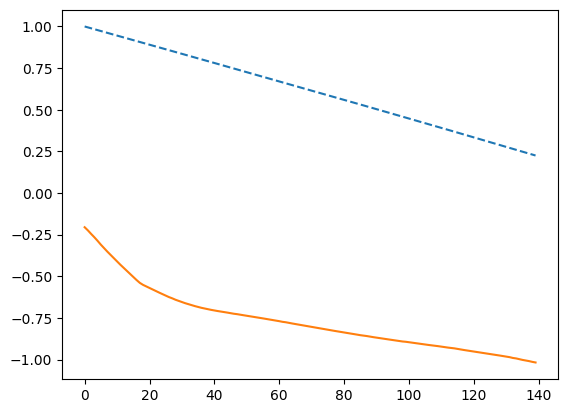

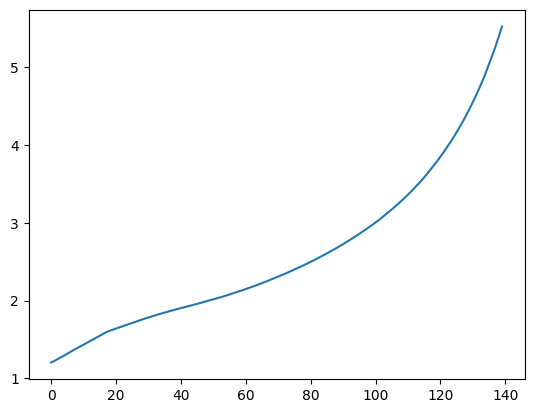

In [179]:
N_dati = 140

y_predict = model.predict(X_eval[0:N_dati,:]).flatten()
error = (Y_eval[0:N_dati]-y_predict)/Y_eval[0:N_dati]

plt.plot(range(len(error)), Y_eval[0:N_dati],linestyle='--',label='known')
plt.plot(range(len(error)), y_predict,label='predicted')
plt.figure()
plt.plot(range(len(error)), error)